# Text-Based Person Retrieval with EmbeddingGemma-2 — RSTPReid (English)

**Task.** Given a free-form English description of a pedestrian, rank a gallery of person images so the images of the described person come first.

**Model.** `google/embeddinggemma-2` used *zero-shot* as a shared text–image embedding space: images are encoded as `<|image|>` inputs, descriptions with the `SearchQuery` prompt, and the ranking is cosine similarity.

**Data.** RSTPReid — 20,505 images of 4,101 identities, 2 English descriptions per image (41,010 descriptions in total).

**Evaluation protocols**

| Protocol | Queries | Gallery | Purpose |
|---|---|---|---|
| **A · Standard test split** | 2,000 test descriptions | 1,000 test images (200 ids) | Comparable with published RSTPReid numbers |
| **B · Entire dataset** | all 41,010 descriptions | all 20,505 images (4,101 ids) | Uses every description of the dataset; much harder (20× larger gallery) |

**Metrics.** Rank-k (CMC: a correct image appears in the top k), mAP (all correct images ranked high), mINP (the *hardest* correct image ranked high).

**Notebook map**
1. Setup · 2. Data · 3. Model · 4. Embeddings · 5. Retrieval metrics · 6. Results (A, B, gallery size, Matryoshka dims) · 7. Qualitative examples · 8. Summary

## 1 · Setup

In [1]:
import json
import random
from collections.abc import Sequence
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.axes import Axes
from PIL import Image
from sentence_transformers import SentenceTransformer

from tbpr import (GRID, INK, INK_2, PLOT_RC, SERIES, CaptionTable, Record, Retrieval, cmc,
                  flatten_captions, load_records, retrieve, summarize)

DATA_ROOT: Path = Path("RSTPReid")
IMG_DIR: Path = DATA_ROOT / "imgs"
OUT_DIR: Path = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

MODEL_ID: str = "google/embeddinggemma-2"
QUERY_PROMPT: str = "SearchQuery"
IMAGE_TOKEN: str = "<|image|>"
IMAGE_BATCH: int = 64
TEXT_BATCH: int = 128
EVAL_CHUNK: int = 1024
FULL_DIM: int = 768
SEED: int = 0

IMAGE_EMB_PATH: Path = OUT_DIR / "image_embeddings.npy"
TEXT_EMB_PATH: Path = OUT_DIR / "caption_embeddings.npy"

DEVICE: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plt.rcParams.update(PLOT_RC)
print("device:", DEVICE)

/home/super/Desktop/Advanced AI Models/Gemma_ebmedding_2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


In [28]:
print(model[0].processor.image_processor)

Gemma4ImageProcessor {
  "do_convert_rgb": true,
  "do_normalize": false,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.0,
    0.0,
    0.0
  ],
  "image_processor_type": "Gemma4ImageProcessor",
  "image_seq_length": 280,
  "image_std": [
    1.0,
    1.0,
    1.0
  ],
  "max_soft_tokens": 280,
  "patch_size": 16,
  "pooling_kernel_size": 3,
  "resample": 3,
  "rescale_factor": 0.00392156862745098
}



## 2 · Data

In [2]:
records: list[Record] = load_records(DATA_ROOT / "data_captions.json")
captions: CaptionTable = flatten_captions(records)
img_pids: np.ndarray = np.array([r.pid for r in records], dtype=np.int64)
img_split: np.ndarray = np.array([r.split for r in records])

missing: list[str] = [r.img_path for r in records if not (IMG_DIR / r.img_path).exists()]
assert not missing, f"{len(missing)} images missing, e.g. {missing[:3]}"

words: np.ndarray = np.array([len(t.split()) for t in captions.texts])
split_stats = pd.DataFrame([
    {
        "split": s,
        "identities": len(set(img_pids[img_split == s])),
        "images": int((img_split == s).sum()),
        "descriptions": int((captions.split == s).sum()),
        "words / description": round(float(words[captions.split == s].mean()), 1),
    }
    for s in ["train", "val", "test"]
])
split_stats.loc[len(split_stats)] = ["ALL", len(set(img_pids)), len(records), len(captions.texts), round(float(words.mean()), 1)]
split_stats

,split,identities,images,descriptions,words / description
0,train,3701,18505,37010,25.8
1,val,200,1000,2000,25.6
2,test,200,1000,2000,25.7
3,ALL,4101,20505,41010,25.8


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


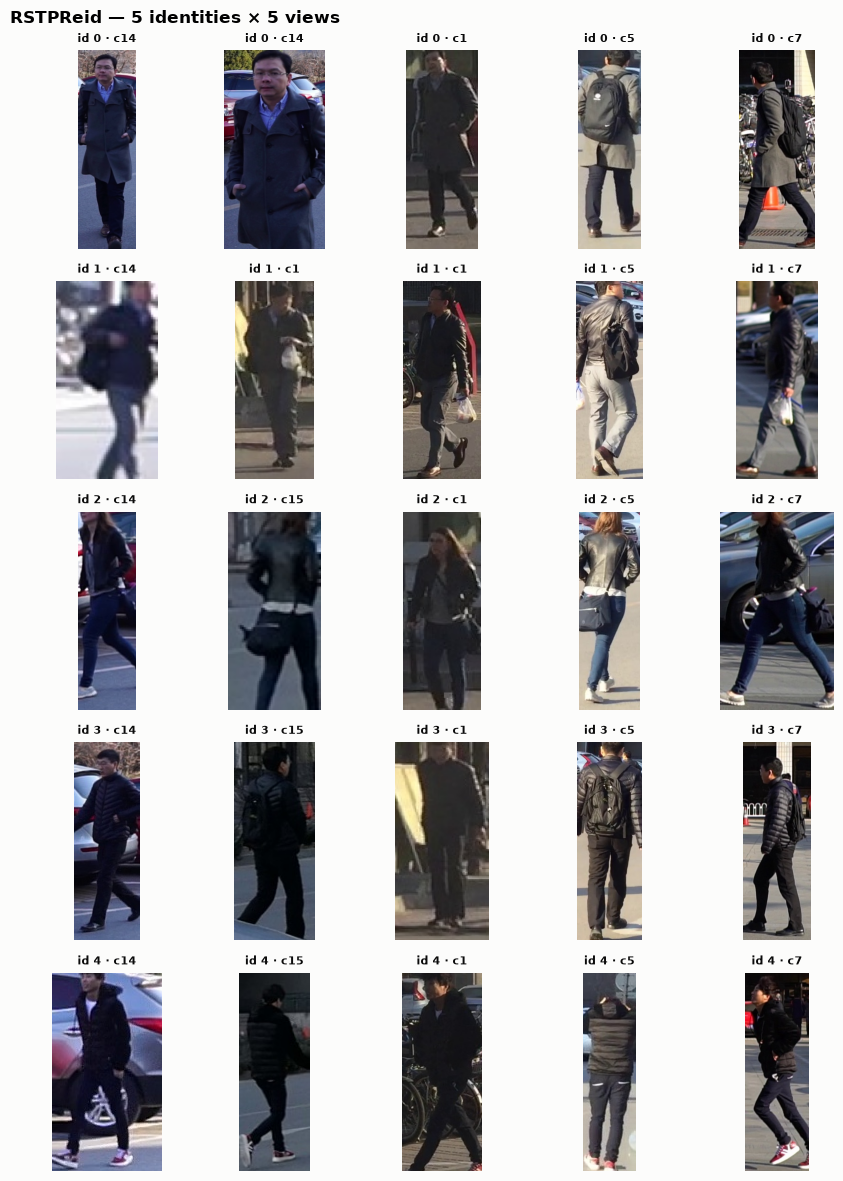

0000_c14_0031.jpg
   - The man is wearing a grey jacket and a blue shirt.His trousers are black and his shoes are brown.He is walking.
   - The man is a strong man who is in a grey jacket.His shirt is blue and his trousers is black.
0000_c14_0032.jpg
   - He is wearing a grey jacket with a blue shirt inside.He put his hands in his pockets.He is wearing a pair of glasses.He is carrying a black bag.
   - The man with glasses is wearing a grey jacket with a blue shirt inside. He has his hands in his pockets.
0000_c1_0004.jpg
   - This is a man wearing a grey jacket.He is walking with his hands in his pockets.His trousers are black.His shoes are brown.
   - The man is walking.He is wearing a dark grey jacket that is close.His trousers is black.He has a pair of brown shoes.
0000_c5_0022.jpg
   - The man is walking with a black bag.He wears a bright jacket and a pair of black trousers.His shoes is dark tanned.
   - A man with black hair, wearing glasses, a gray and black shirt, black pants a

In [3]:
# Five identities, five camera views each (captions shown under the grid)
first_pids: list[int] = list(dict.fromkeys(r.pid for r in records))[:5]
sample: list[Record] = [r for r in records if r.pid in first_pids]

fig, axes = plt.subplots(5, 5, figsize=(9, 12))
for ax, r in zip(axes.flat, sample):
    ax.imshow(Image.open(IMG_DIR / r.img_path))
    ax.set_title(f"id {r.pid} · {r.img_path.split('_')[1]}", fontsize=8, loc="center")
    ax.axis("off")
fig.suptitle("RSTPReid — 5 identities × 5 views", x=0.02, ha="left", fontweight="semibold")
plt.tight_layout()
plt.show()

for r in sample[:5]:
    print(f"{r.img_path}")
    for c in r.captions:
        print(f"   - {c}")

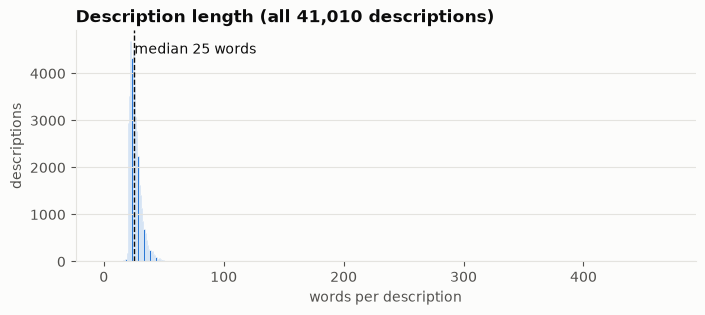

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(words, bins=range(0, int(words.max()) + 2), color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(float(np.median(words)), color=INK, linewidth=1, linestyle="--")
ax.text(float(np.median(words)) + 0.5, ax.get_ylim()[1] * 0.9, f"median {np.median(words):.0f} words", color=INK)
ax.set_title("Description length (all 41,010 descriptions)")
ax.set_xlabel("words per description"); ax.set_ylabel("descriptions")
ax.grid(axis="x", visible=False)
plt.show()

## 3 · Model

In [5]:
dtype: torch.dtype = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
model = SentenceTransformer(
    MODEL_ID,
    device=str(DEVICE),
    model_kwargs={"torch_dtype": dtype},
    config_kwargs={"audio_config": None},   # audio encoder not needed
)
print("loaded on", model.device, "|", dtype, "| query prompt:", repr(model.prompts[QUERY_PROMPT]))


Loading weights:   0%|          | 0/624 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 624/624 [00:00<00:00, 11574.23it/s]

loaded on cuda:0 | torch.bfloat16 | query prompt: 'task: search result | query: '


## 4 · Embeddings

Every image and every description is encoded once and cached to `outputs/` (the web demo reuses `image_embeddings.npy`). Delete the files to force re-encoding. Encoding the 20,505 images takes ≈15 min on an RTX 3090.

In [6]:
def encode_images(paths: Sequence[Path], batch_size: int) -> np.ndarray:
    inputs: list[dict[str, str]] = [{"text": IMAGE_TOKEN, "image": str(p)} for p in paths]
    emb = model.encode(inputs, batch_size=batch_size, normalize_embeddings=True,
                       convert_to_numpy=True, show_progress_bar=True)
    return emb.astype(np.float32)


def encode_queries(texts: Sequence[str], batch_size: int) -> np.ndarray:
    emb = model.encode(list(texts), prompt_name=QUERY_PROMPT, batch_size=batch_size,
                       normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True)
    return emb.astype(np.float32)


def cached_embeddings(path: Path, expected_rows: int) -> np.ndarray | None:
    if not path.exists():
        return None
    emb: np.ndarray = np.load(path)
    if emb.shape != (expected_rows, FULL_DIM):
        raise ValueError(f"stale cache {path}: shape {emb.shape}, expected ({expected_rows}, {FULL_DIM})")
    return emb


img_emb_np: np.ndarray | None = cached_embeddings(IMAGE_EMB_PATH, len(records))
if img_emb_np is None:
    img_emb_np = encode_images([IMG_DIR / r.img_path for r in records], IMAGE_BATCH)
    np.save(IMAGE_EMB_PATH, img_emb_np)

txt_emb_np: np.ndarray | None = cached_embeddings(TEXT_EMB_PATH, len(captions.texts))
if txt_emb_np is None:
    txt_emb_np = encode_queries(captions.texts, TEXT_BATCH)
    np.save(TEXT_EMB_PATH, txt_emb_np)

img_emb: torch.Tensor = torch.from_numpy(img_emb_np).to(DEVICE)
txt_emb: torch.Tensor = torch.from_numpy(txt_emb_np).to(DEVICE)
print("images:", tuple(img_emb.shape), "| descriptions:", tuple(txt_emb.shape))


Batches:   0%|          | 0/321 [00:00<?, ?it/s]

[transformers] Image decoding with `torchvision` is deprecated and will be removed in future versions .Please install `torchcodec>=0.16.0` instead. 



Batches:   0%|          | 1/321 [00:03<16:44,  3.14s/it]


Batches:   1%|          | 2/321 [00:06<15:52,  2.99s/it]


Batches:   1%|          | 3/321 [00:08<15:32,  2.93s/it]


Batches:   1%|          | 4/321 [00:11<15:22,  2.91s/it]

... (519 outputs left out)


Batches:  99%|█████████▉| 318/321 [00:31<00:00, 12.45it/s]


Batches: 100%|█████████▉| 320/321 [00:31<00:00, 12.51it/s]


Batches: 100%|██████████| 321/321 [00:31<00:00, 10.12it/s]

images: (20505, 768) | descriptions: (41010, 768)


## 5 · Retrieval metrics

For each query the whole gallery is sorted by cosine similarity (on GPU, in chunks).
* **Rank-k** — share of queries whose *first* correct image is within the top k.
* **mAP** — mean average precision over *all* correct images of the person.
* **mINP** — mean inverse negative penalty: `#correct / rank of the last correct image`.

`dim < 768` truncates both embeddings (Matryoshka) and re-normalizes.

Implemented in `tbpr.py` (`retrieve`, `summarize`, `cmc`) and shared with `TBPR_finetune.ipynb`.

## 6 · Results
### 6.1 Protocol A (standard test split) vs Protocol B (entire dataset)

In [8]:
@dataclass(frozen=True)
class Protocol:
    name: str
    q_idx: np.ndarray   # indices into `captions`
    g_idx: np.ndarray   # indices into `records`


def protocol_for_split(name: str, split: str) -> Protocol:
    return Protocol(name, np.flatnonzero(captions.split == split), np.flatnonzero(img_split == split))


def run(p: Protocol, dim: int) -> Retrieval:
    return retrieve(txt_emb[p.q_idx], captions.pids[p.q_idx], img_emb[p.g_idx], img_pids[p.g_idx], dim, EVAL_CHUNK)


PROTO_A: Protocol = protocol_for_split("A · test split", "test")
PROTO_B: Protocol = Protocol("B · entire dataset", np.arange(len(captions.texts)), np.arange(len(records)))

res_a: Retrieval = run(PROTO_A, FULL_DIM)
res_b: Retrieval = run(PROTO_B, FULL_DIM)

main = pd.DataFrame([
    {"protocol": p.name, "queries": len(p.q_idx), "gallery": len(p.g_idx),
     "identities": len(set(img_pids[p.g_idx])), **summarize(r)}
    for p, r in [(PROTO_A, res_a), (PROTO_B, res_b)]
])
main.to_csv(OUT_DIR / "results_main.csv", index=False)
main.round(2)

,protocol,queries,gallery,identities,Rank-1,Rank-5,Rank-10,mAP,mINP
0,A · test split,2000,1000,200,35.45,59.50,70.00,25.00,7.59
1,B · entire dataset,41010,20505,4101,10.00,20.92,27.31,6.19,0.79


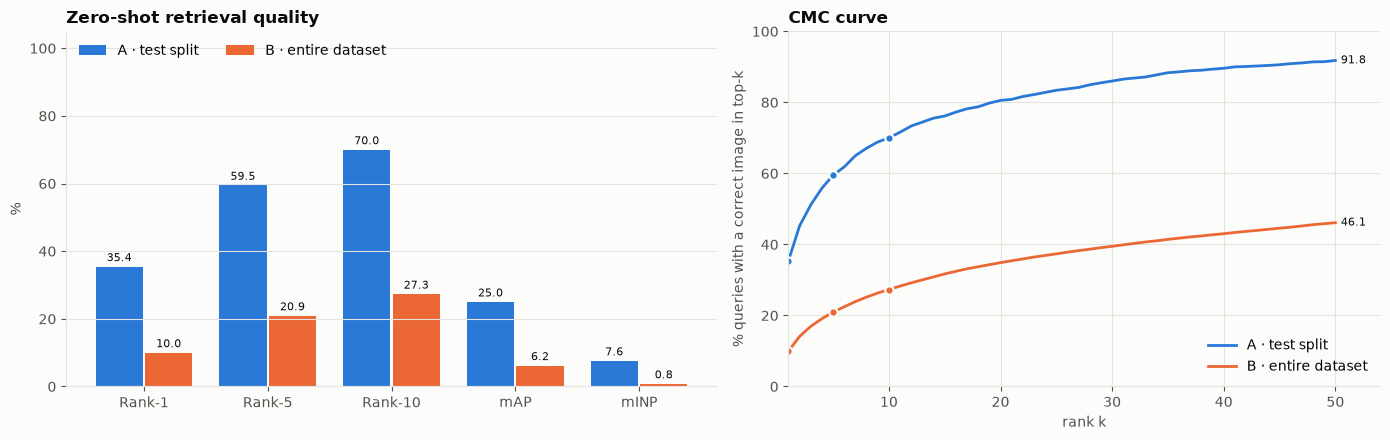

In [9]:
METRICS: list[str] = ["Rank-1", "Rank-5", "Rank-10", "mAP", "mINP"]
x = np.arange(len(METRICS))
w = 0.38

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.1, 1]})
for i, (_, row) in enumerate(main.iterrows()):
    vals = [row[m] for m in METRICS]
    bars = ax1.bar(x + (i - 0.5) * (w + 0.02), vals, w, color=SERIES[i], label=row["protocol"])
    ax1.bar_label(bars, fmt="%.1f", padding=2, fontsize=8, color=INK)
ax1.set_xticks(x, METRICS); ax1.set_ylim(0, 105); ax1.set_ylabel("%")
ax1.grid(axis="x", visible=False)
ax1.set_title("Zero-shot retrieval quality")
ax1.legend(loc="upper left", ncols=2)

K: int = 50
for i, (p, r) in enumerate([(PROTO_A, res_a), (PROTO_B, res_b)]):
    curve = cmc(r, K)
    ax2.plot(range(1, K + 1), curve, color=SERIES[i], label=p.name)
    for k in (1, 5, 10):
        ax2.plot(k, curve[k - 1], "o", color=SERIES[i], markersize=6, markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    ax2.annotate(f"{curve[-1]:.1f}", (K, curve[-1]), xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=8)
ax2.set_xlim(1, K + 4); ax2.set_ylim(0, 100)
ax2.set_xlabel("rank k"); ax2.set_ylabel("% queries with a correct image in top-k")
ax2.set_title("CMC curve")
ax2.legend(loc="lower right")
plt.tight_layout()
fig.savefig(OUT_DIR / "results_main.png", dpi=150)
plt.show()

### 6.2 How gallery size drives difficulty

Protocol B is not just "more data" — every query competes against 20× more distractors. To separate the two effects, identities are sampled from the full dataset (3 random draws per size, seed fixed) and the retrieval is re-run on just their images and descriptions.

In [10]:
def protocol_for_ids(name: str, ids: set[int]) -> Protocol:
    return Protocol(name, np.flatnonzero(np.isin(captions.pids, list(ids))), np.flatnonzero(np.isin(img_pids, list(ids))))


all_ids: list[int] = sorted(set(img_pids.tolist()))
SIZES: list[int] = [50, 100, 200, 500, 1000, 2000, len(all_ids)]
rng = random.Random(SEED)
scale_rows: list[dict[str, float]] = []
for n in SIZES:
    draws = 1 if n == len(all_ids) else 3
    for d in range(draws):
        ids = set(rng.sample(all_ids, n))
        r = run(protocol_for_ids(f"{n} ids", ids), FULL_DIM)
        scale_rows.append({"identities": n, "draw": d, "gallery": int(np.isin(img_pids, list(ids)).sum()), **summarize(r)})

scale = pd.DataFrame(scale_rows).groupby("identities").mean(numeric_only=True).drop(columns="draw").reset_index()
scale.to_csv(OUT_DIR / "results_gallery_size.csv", index=False)
scale.round(2)

,identities,gallery,Rank-1,Rank-5,Rank-10,mAP,mINP
0,50,250.0,46.33,73.53,84.80,37.31,16.51
1,100,500.0,38.33,62.07,72.17,28.71,10.27
2,200,1000.0,33.38,55.22,64.93,23.81,7.18
3,500,2500.0,23.49,42.87,53.01,16.25,3.77
4,1000,5000.0,17.82,34.48,42.97,11.68,2.21
5,2000,10000.0,13.82,27.26,34.85,8.75,1.38
6,4101,20505.0,10.00,20.92,27.31,6.19,0.79


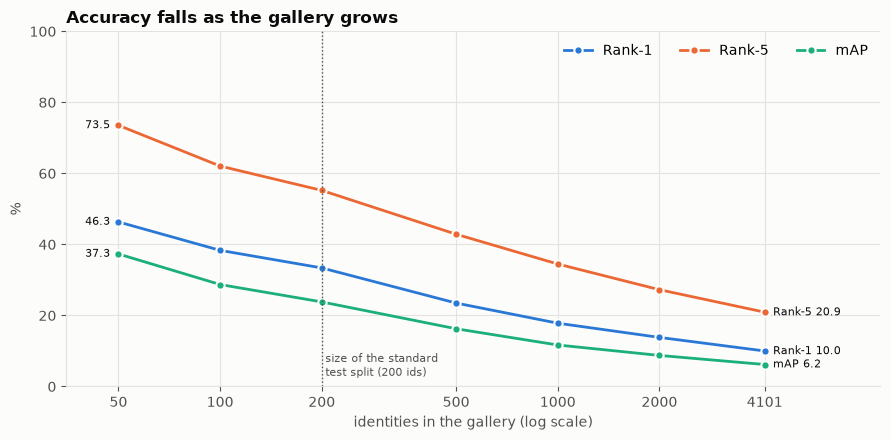

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, m in enumerate(["Rank-1", "Rank-5", "mAP"]):
    ax.plot(scale.identities, scale[m], color=SERIES[i], marker="o", markersize=6,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=m)
    ax.annotate(f"{m} {scale[m].iloc[-1]:.1f}", (scale.identities.iloc[-1], scale[m].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
    ax.annotate(f"{scale[m].iloc[0]:.1f}", (scale.identities.iloc[0], scale[m].iloc[0]),
                xytext=(-6, 0), textcoords="offset points", va="center", ha="right", fontsize=8, color=INK)
ax.axvline(200, color=INK_2, linewidth=1, linestyle=":")
ax.text(205, 3, "size of the standard\ntest split (200 ids)", fontsize=8, color=INK_2)
ax.set_xscale("log"); ax.set_xticks(SIZES, [str(s) for s in SIZES]); ax.minorticks_off()
ax.set_xlim(35, 9000); ax.set_ylim(0, 100)
ax.set_xlabel("identities in the gallery (log scale)"); ax.set_ylabel("%")
ax.set_title("Accuracy falls as the gallery grows")
ax.legend(loc="upper right", ncols=3)
plt.tight_layout()
fig.savefig(OUT_DIR / "results_gallery_size.png", dpi=150)
plt.show()

### 6.3 Matryoshka: smaller embeddings
EmbeddingGemma is trained so the first *d* dimensions still form a usable embedding.

In [12]:
DIMS: list[int] = [768, 512, 256, 128]
dim_rows: list[dict[str, float | str | int]] = [
    {"protocol": p.name, "dim": d, **summarize(run(p, d))}
    for p in (PROTO_A, PROTO_B) for d in DIMS
]
dims = pd.DataFrame(dim_rows)
dims.to_csv(OUT_DIR / "results_dims.csv", index=False)
dims.round(2)

,protocol,dim,Rank-1,Rank-5,Rank-10,mAP,mINP
0,A · test split,768,35.45,59.50,70.00,25.00,7.59
1,A · test split,512,35.10,58.45,69.75,24.19,7.46
2,A · test split,256,30.60,54.90,66.55,22.21,6.78
3,A · test split,128,24.25,47.90,59.55,17.06,4.33
4,B · entire dataset,768,10.00,20.92,27.31,6.19,0.79
5,B · entire dataset,512,9.50,20.22,26.33,5.93,0.75
6,B · entire dataset,256,8.16,17.51,23.37,5.09,0.61
7,B · entire dataset,128,5.70,13.28,18.69,3.64,0.39


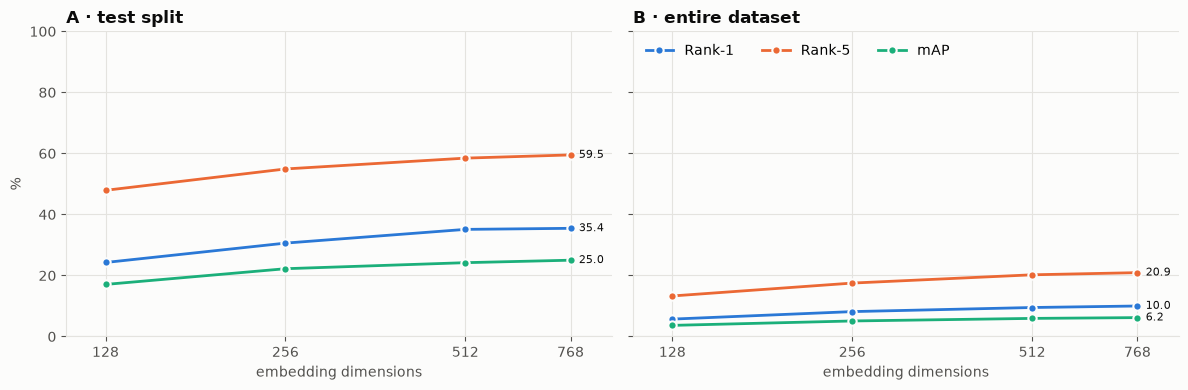

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, p in zip(axes, (PROTO_A, PROTO_B)):
    sub = dims[dims.protocol == p.name]
    for i, m in enumerate(["Rank-1", "Rank-5", "mAP"]):
        ax.plot(sub.dim, sub[m], color=SERIES[i], marker="o", markersize=6,
                markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=m)
        ax.annotate(f"{sub[m].iloc[0]:.1f}", (768, sub[m].iloc[0]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8, color=INK)
    ax.set_xscale("log", base=2); ax.set_xticks(DIMS, [str(d) for d in DIMS]); ax.minorticks_off()
    ax.set_xlim(110, 900); ax.set_ylim(0, 100)
    ax.set_title(p.name); ax.set_xlabel("embedding dimensions")
axes[0].set_ylabel("%")
axes[1].legend(loc="upper left", ncols=3)
plt.tight_layout()
fig.savefig(OUT_DIR / "results_dims.png", dpi=150)
plt.show()

### 6.4 Where does the first correct image land?

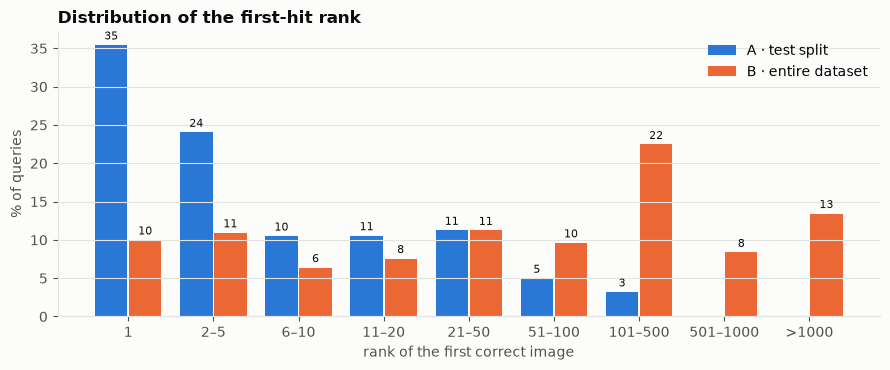

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.array([1, 2, 6, 11, 21, 51, 101, 501, 1001, 20506])
labels = ["1", "2–5", "6–10", "11–20", "21–50", "51–100", "101–500", "501–1000", ">1000"]
for i, (p, r) in enumerate([(PROTO_A, res_a), (PROTO_B, res_b)]):
    counts, _ = np.histogram(r.first_hit, bins=bins)
    share = 100 * counts / len(r.first_hit)
    pos = np.arange(len(labels)) + (i - 0.5) * 0.4
    bars = ax.bar(pos, share, 0.38, color=SERIES[i], label=p.name)
    ax.bar_label(bars, labels=[f"{v:.0f}" if v >= 1 else "" for v in share], padding=2, fontsize=8, color=INK)
ax.set_xticks(np.arange(len(labels)), labels)
ax.set_xlabel("rank of the first correct image"); ax.set_ylabel("% of queries")
ax.grid(axis="x", visible=False)
ax.set_title("Distribution of the first-hit rank")
ax.legend(loc="upper right")
plt.tight_layout()
fig.savefig(OUT_DIR / "results_first_hit.png", dpi=150)
plt.show()

## 7 · Qualitative examples (Protocol A)
Top-5 images per description. **Aqua frame = correct person**, orange frame = wrong person.

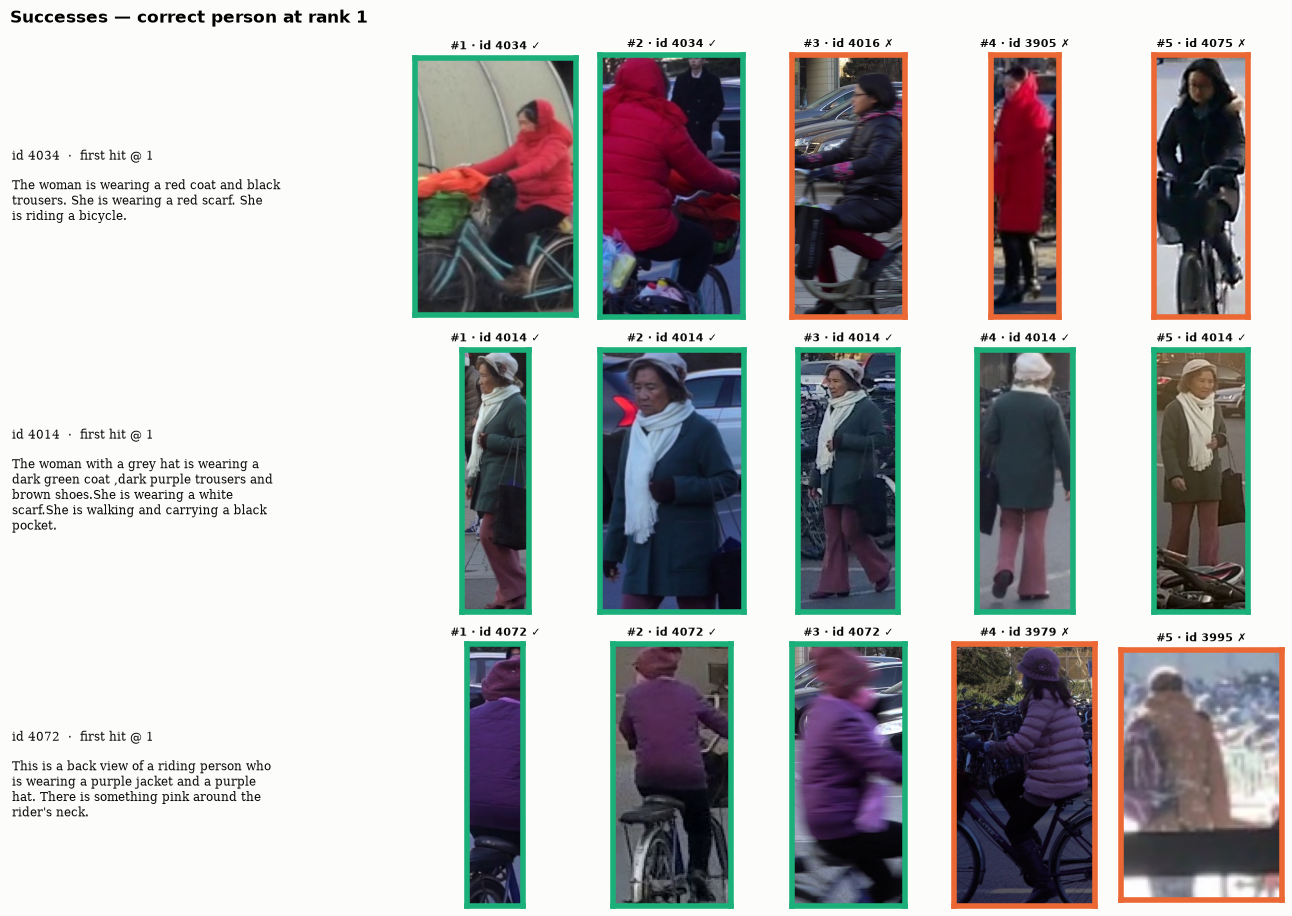

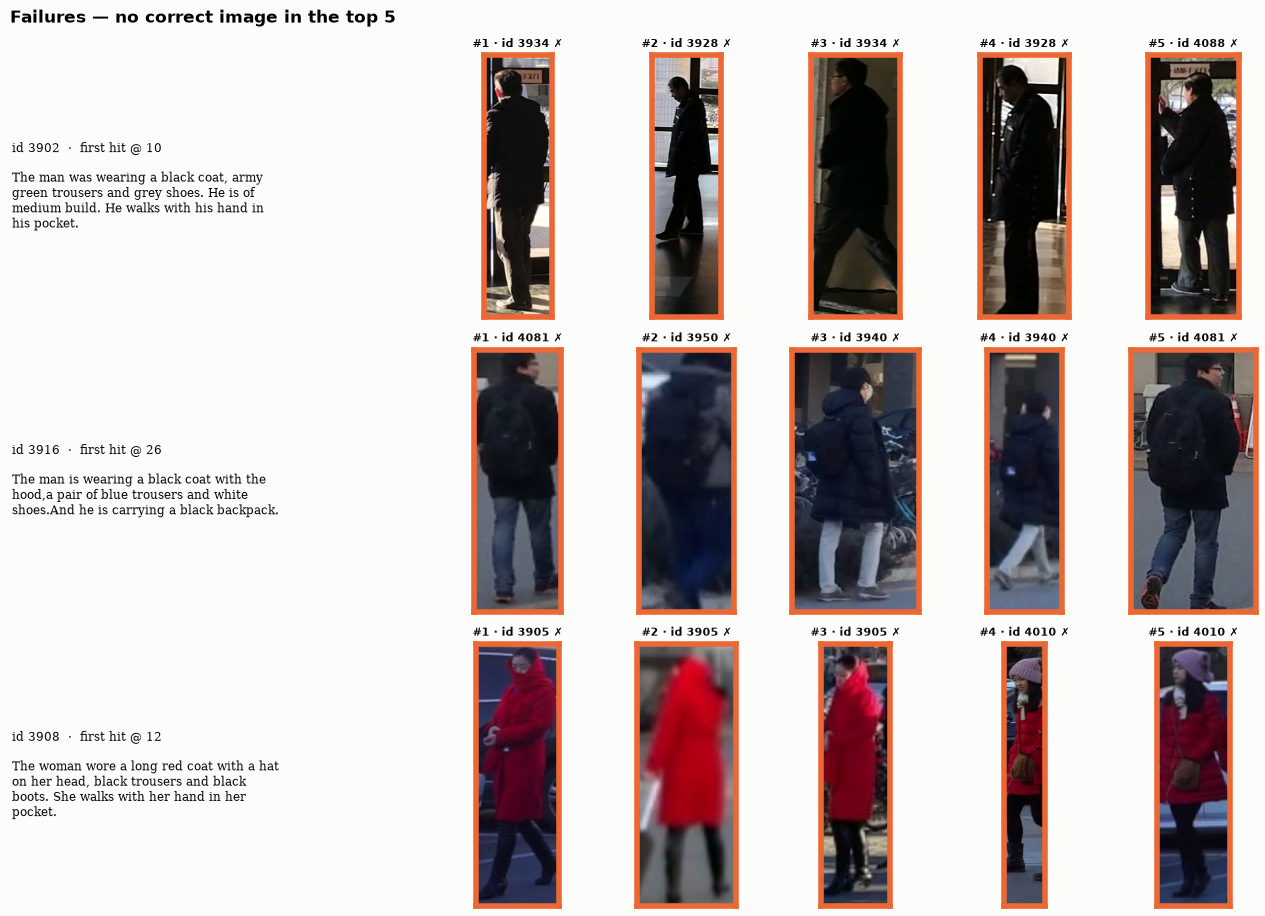

In [15]:
def _wrap(text: str, width: int) -> str:
    out, line = [], ""
    for w in text.split():
        if len(line) + len(w) + 1 > width:
            out.append(line); line = w
        else:
            line = f"{line} {w}".strip()
    return "\n".join(out + [line])


def show_queries(p: Protocol, r: Retrieval, rows: Sequence[int], title: str) -> None:
    fig, axes = plt.subplots(len(rows), 6, figsize=(13, 3.1 * len(rows)),
                             gridspec_kw={"width_ratios": [2.4, 1, 1, 1, 1, 1]})
    for line, qi in zip(axes, rows):
        cap_i = int(p.q_idx[qi])
        pid = int(captions.pids[cap_i])
        line[0].axis("off")
        line[0].text(0, 0.5, f"id {pid}  ·  first hit @ {r.first_hit[qi]}\n\n" + _wrap(captions.texts[cap_i], 42),
                     va="center", fontsize=8.5, color=INK, family="serif")
        for k, (ax, gi) in enumerate(zip(line[1:], r.top5[qi])):
            rec = records[int(p.g_idx[gi])]
            ok = rec.pid == pid
            ax.imshow(Image.open(IMG_DIR / rec.img_path))
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_visible(True); s.set_edgecolor(SERIES[2] if ok else SERIES[1]); s.set_linewidth(4)
            ax.set_title(f"#{k + 1} · id {rec.pid} {'✓' if ok else '✗'}", fontsize=8, loc="center")
    fig.suptitle(title, x=0.01, ha="left", fontweight="semibold")
    plt.tight_layout()
    plt.show()


qrng = np.random.default_rng(SEED)
hits = np.flatnonzero(res_a.first_hit == 1)
misses = np.flatnonzero(res_a.first_hit > 5)
show_queries(PROTO_A, res_a, qrng.choice(hits, 3, replace=False).tolist(), "Successes — correct person at rank 1")
show_queries(PROTO_A, res_a, qrng.choice(misses, 3, replace=False).tolist(), "Failures — no correct image in the top 5")

## 8 · Summary

In [16]:
print(main[["protocol", "gallery", "identities", *METRICS]].round(1).to_string(index=False))
print("\nArtifacts in", OUT_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print("  ", f.name)

          protocol  gallery  identities  Rank-1  Rank-5  Rank-10  mAP  mINP
    A · test split     1000         200    35.4    59.5     70.0 25.0   7.6
B · entire dataset    20505        4101    10.0    20.9     27.3  6.2   0.8

Artifacts in /home/super/Desktop/Advanced AI Models/Gemma_ebmedding_2/outputs
   caption_embeddings.npy
   image_embeddings.npy
   results_dims.csv
   results_dims.png
   results_first_hit.png
   results_gallery_size.csv
   results_gallery_size.png
   results_main.csv
   results_main.png


### Findings

| Protocol | Gallery | Rank-1 | Rank-5 | Rank-10 | mAP | mINP |
|---|---|---|---|---|---|---|
| A · test split | 1,000 imgs / 200 ids | **35.5** | 59.5 | 70.0 | 25.0 | 7.6 |
| B · entire dataset | 20,505 imgs / 4,101 ids | **10.0** | 20.9 | 27.3 | 6.2 | 0.8 |

* **Zero-shot EmbeddingGemma-2 works for person retrieval.** On the standard test split, the correct person is the top-1 match for 35% of descriptions and appears in the top 10 for 70%, even though the model was never trained on RSTPReid. Published supervised RSTPReid methods report about 60–70% Rank-1, so this is a fair zero-shot baseline but not state of the art.
* **The drop from A to B is mostly a gallery-size effect, not a data-quality one.** Random galleries of 200 ids from the full dataset give 33.4% Rank-1, almost the same as the official test split. Rank-1 then falls steadily as identities are added: 46% at 50 ids, 10% at 4,101 ids. The 72% Rank-1 of the earlier 5-person pilot came from its tiny 25-image gallery.
* **Matryoshka truncation is nearly free down to 512 dims** (−0.4 Rank-1 on A). At 256 dims Rank-1 drops about 5 points, and at 128 dims about 11 points.
* **Failures are near-misses.** Typical errors rank other people with the same dominant clothing colour first (e.g. "red coat" → other red-coat wearers). The model matches colour and garment well, but not fine details such as shoes, hats or bags.
* mINP is low in both protocols: the *hardest* view of a person (back view, occlusion, low light) is often ranked far down.